# 03 Risk: exposure-adjusted rates (H3) and general kidnapping (H4)

Confirmatory tests of H3 and H4 as fixed in `docs/preregistration.md` (tag `prereg-v1`, amendments in section 8). Data: the incident register (`data/processed/incidents.csv`), modelled exposure (`data/processed/exposure_by_state.csv`) [A09, A10], and for H4 the general kidnapping series (`data/processed/general_kidnapping_by_state.csv`) and the Nigeria Watch series (`data/processed/nigeria_watch_kidnapping_by_state.csv`). Period: 1 January 2010 to the data cutoff of 5 October 2026 [A15]. Alpha = 0.05.

In [1]:
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from nysc_safety import figures, paths, risk

figures.style()
CUTOFF = date(2026, 10, 5)  # [A15]
TABLES = paths.ROOT / "reports" / "tables"
TABLES.mkdir(parents=True, exist_ok=True)

incidents = pd.read_csv(paths.DATA_PROCESSED / "incidents.csv")
exposure = pd.read_csv(paths.DATA_PROCESSED / "exposure_by_state.csv")
course_figures = pd.read_csv(paths.DATA_INTERIM / "exposure" / "state_course_figures.csv")
national = pd.read_csv(paths.DATA_INTERIM / "exposure" / "national_totals.csv")
incident_sources = figures.id_ranges(s for ids in incidents["source_ids"] for s in ids.split(";"))
exposure_sources = figures.id_ranges(
    [s for ids in course_figures["source_id"].dropna() for s in str(ids).split(";")]
    + [s for ids in national["source_id"].dropna() for s in str(ids).split(";")]
)
print(f"Incident sources: {incident_sources}; exposure sources: {exposure_sources}")

Incident sources: S18-S20, S22-S146, S148-S153; exposure sources: S155-S366


## H3: do incident rates differ across states?

The pre-registered test is a Poisson regression of state incident counts with log exposure as offset, compared by a likelihood-ratio test with an intercept-only model, switching to a negative binomial model if the Pearson dispersion statistic exceeds 1.5. Counts are modelled by state and year (37 states by 17 years), because a model with one count per state and one term per state fits the data exactly and leaves no residual degrees of freedom for the dispersion check (pre-registration amendment of 2026-10-08). Exposure in 2026 is scaled to the share of the year before the cutoff. States with fewer than 1,000 corps members exposed over the period are excluded and listed.

In [2]:
panel = risk.state_year_panel(incidents, exposure, CUTOFF)
panel, small = risk.drop_small_states(panel)
print(f"States excluded for exposure below 1,000: {small or 'none'}")
print(f"{panel['incidents'].sum()} incidents, {panel['exposure'].sum():,.0f} corps-member years of exposure, {panel['state'].nunique()} states")
h3 = risk.h3_test(panel)
pd.Series(h3).to_frame("value")

States excluded for exposure below 1,000: none
96 incidents, 5,096,391 corps-member years of exposure, 37 states


,value
model,poisson
n_obs,629
n_states,37
incidents,96
dispersion_poisson,0.844477
nb_alpha,NaN
lr_statistic,90.205374
df,36
p_value,0.000002


In [3]:
state_table = risk.state_rates(panel)
state_table.to_csv(TABLES / "h3_state_rates.csv", index=False)
state_table.round({"exposed": 0, "rate": 2, "ci_lower": 2, "ci_upper": 2}).head(12)

,state,zone,incidents,exposed,rate,ci_lower,ci_upper,rank_count,rank_rate
0,Akwa Ibom,South South,8,122359.0,0.65,0.28,1.29,3,1
1,Rivers,South South,10,162732.0,0.61,0.29,1.13,1,2
2,Katsina,North West,5,87645.0,0.57,0.19,1.33,5,3
3,FCT,North Central,10,178465.0,0.56,0.27,1.03,1,4
4,Bayelsa,South South,6,124415.0,0.48,0.18,1.05,4,5
5,Zamfara,North West,4,91208.0,0.44,0.12,1.12,6,6
6,Kaduna,North West,4,110040.0,0.36,0.10,0.93,6,7
7,Anambra,South East,4,116237.0,0.34,0.09,0.88,6,8
8,Kogi,North Central,4,120113.0,0.33,0.09,0.85,6,9
9,Benue,North Central,4,139486.0,0.29,0.08,0.73,6,10


In [4]:
from scipy import stats as st
rank_rho = st.spearmanr(state_table["incidents"], state_table["rate"])[0]
moved = state_table[(state_table["rank_count"] - state_table["rank_rate"]).abs() >= 5]
print(f"Spearman correlation of state ranks by count and by rate: {rank_rho:.3f}")
print(f"States whose rank changes by 5 or more places: {len(moved)}")
moved[["state", "incidents", "rate", "rank_count", "rank_rate"]].round(2)

Spearman correlation of state ranks by count and by rate: 0.962
States whose rank changes by 5 or more places: 11


,state,incidents,rate,rank_count,rank_rate
10,Plateau,4,0.27,6,11
13,Ogun,4,0.20,6,14
23,Cross River,1,0.08,19,24
24,Kano,1,0.08,19,25
25,Jigawa,1,0.07,19,26
26,Niger,1,0.06,19,27
27,Delta,1,0.06,19,28
28,Kwara,1,0.06,19,29
29,Osun,1,0.06,19,30
30,Oyo,1,0.05,19,31


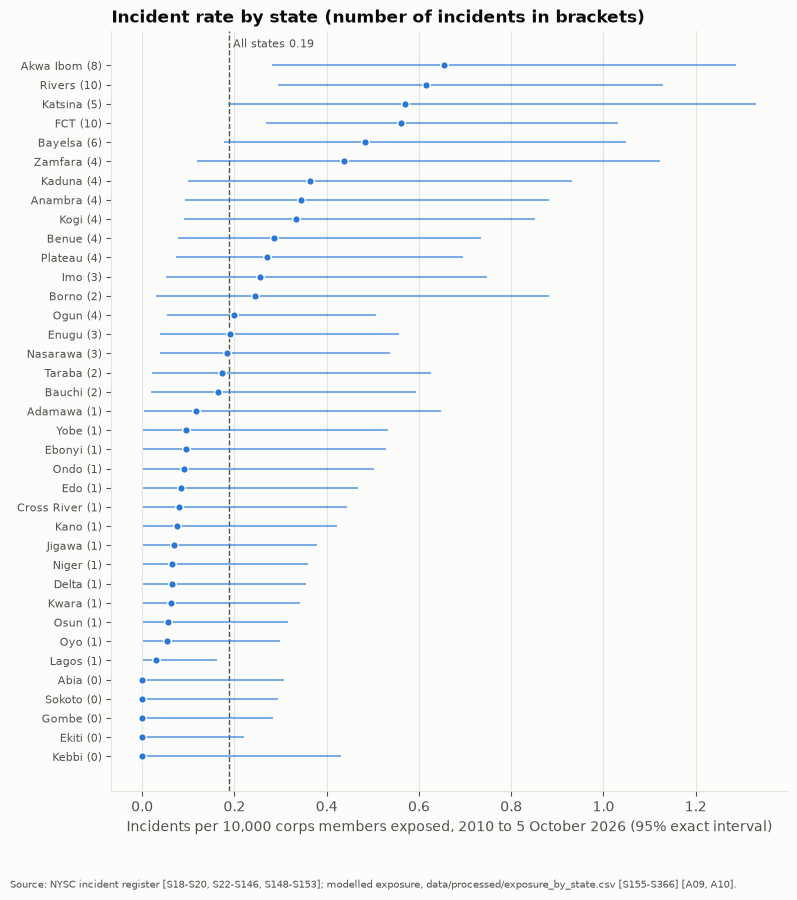

In [5]:
plot = state_table.sort_values("rate")
fig, ax = plt.subplots(figsize=(8, 9))
y = np.arange(len(plot))
ax.hlines(y, plot["ci_lower"], plot["ci_upper"], color=figures.SERIES[0], linewidth=1.5, alpha=0.6, zorder=2)
ax.scatter(plot["rate"], y, s=30, color=figures.SERIES[0], edgecolor="white", linewidth=1, zorder=3)
national_rate = panel["incidents"].sum() / panel["exposure"].sum() * 10_000
ax.axvline(national_rate, color=figures.TEXT_SECONDARY, linewidth=1, linestyle="--", zorder=1)
ax.text(national_rate, len(plot) - 0.2, f" All states {national_rate:.2f}", color=figures.TEXT_SECONDARY, fontsize=8, va="bottom")
ax.set_yticks(y, [f"{s} ({n})" for s, n in zip(plot["state"], plot["incidents"])], fontsize=8)
ax.set_xlabel("Incidents per 10,000 corps members exposed, 2010 to 5 October 2026 (95% exact interval)")
ax.set_title("Incident rate by state (number of incidents in brackets)")
ax.grid(axis="y", visible=False)
figures.save(fig, "h3_incident_rate_by_state",
             f"NYSC incident register [{incident_sources}]; modelled exposure, data/processed/exposure_by_state.csv "
             f"[{exposure_sources}] [A09, A10].")
plt.show()

### H3 robustness

Pre-registered checks: a two-year exposure window [A02]; the test without the five states with the most incidents. Checks set out in A09: exposure shares from sworn-in figures only, and from figures for batches from 2019 onwards only, with the states each variant leaves out listed.

In [6]:
variants = {}
variants["Main"] = (panel, [])
variants["Two-year exposure window"] = (risk.drop_small_states(risk.state_year_panel(incidents, exposure, CUTOFF, window_years=2))[0], [])
top5 = risk.top_states(panel, 5)
variants["Without five states with most incidents"] = (panel[~panel["state"].isin(top5)], top5)
for name, kwargs in {"A09: sworn-in figures only": dict(count_types=("sworn_in",)),
                     "A09: figures for 2019 onwards only": dict(min_batch_year=2019)}.items():
    table = risk.exposure_variant(course_figures, national, **kwargs)
    missing = sorted(set(exposure["state"]) - set(table["state"]))
    variants[name] = (risk.drop_small_states(risk.state_year_panel(incidents, table, CUTOFF))[0], missing)

rows, rankings = {}, {}
for name, (p, left_out) in variants.items():
    rows[name] = {**risk.h3_test(p), "states_left_out": "; ".join(left_out)}
    rankings[name] = risk.state_rates(p).set_index("state")["rate"]
h3_robust = pd.DataFrame(rows).T
h3_robust.to_csv(TABLES / "h3_robustness.csv")
print(f"Five states with most incidents: {top5}")
h3_robust

Five states with most incidents: ['FCT', 'Rivers', 'Akwa Ibom', 'Bayelsa', 'Katsina']


,model,n_obs,n_states,incidents,dispersion_poisson,nb_alpha,lr_statistic,df,p_value,states_left_out
Main,poisson,629,37,96,0.844477,NaN,90.205374,36,0.000002,
Two-year exposure window,poisson,629,37,96,0.82928,NaN,90.205378,36,0.000002,
Without five states with most incidents,poisson,544,32,57,0.816035,NaN,45.696718,31,0.043161,FCT; Rivers; Akwa Ibom; Bayelsa; Katsina
A09: sworn-in figures only,poisson,476,28,79,0.865716,NaN,78.274486,27,0.000001,Borno; Ebonyi; Gombe; Katsina; Niger; Ogun; On...
A09: figures for 2019 onwards only,poisson,629,37,96,0.844467,NaN,95.400827,36,0.0,


In [7]:
rank_check = pd.DataFrame(rankings)
pd.Series({c: rank_check[["Main", c]].dropna().corr(method="spearman").iloc[0, 1] for c in rank_check.columns[1:]},
          name="Spearman with main state rates").round(3).to_frame()

,Spearman with main state rates
Two-year exposure window,1.000
Without five states with most incidents,1.000
A09: sworn-in figures only,0.974
A09: figures for 2019 onwards only,0.987


### H3 result

Over 1 January 2010 to 5 October 2026, the register has 96 incidents against about 5.1 million corps members deployed in modelled exposure, an overall rate of 0.19 incidents per 10,000 [A09, A10]. No state falls below the 1,000-exposed threshold. The Pearson dispersion statistic of the Poisson state model is 0.84, below the 1.5 limit, so the Poisson model is used. The likelihood-ratio test of the 36 state terms against the intercept-only model gives a statistic of 90.2 (df = 36, p = 0.000002). H3 is supported: incident rates per 10,000 corps members differ across states.

The highest rates are in Akwa Ibom (0.65 per 10,000, 8 incidents), Rivers (0.61, 10), Katsina (0.57, 5), the FCT (0.56, 10) and Bayelsa (0.48, 6). Five states have no recorded incident (Abia, Ekiti, Gombe, Kebbi, Sokoto). The intervals are wide, and those of most states overlap.

The ranking by rate is close to the ranking by count (Spearman 0.962). Eleven states move five or more places, almost all of them states with one incident whose tied count rank is broken by exposure. The prediction that rankings by rate differ from rankings by raw count therefore holds only weakly. Under A09 each state's exposure is a fixed share of the national total, so differences in exposure across states are moderate and stable over time, and rates largely follow counts.

Robustness: the result holds with a two-year exposure window (p = 0.000002), with exposure shares from sworn-in figures only (28 states, p = 0.000001) and from figures for 2019 onwards only (p < 0.000001). Without the five states with the most incidents (the FCT, Rivers, Akwa Ibom, Bayelsa and Katsina) the remaining 32 states still differ, more weakly (p = 0.043). Under A09 the two-year window changes exposure in every state by the same factor in each year, so it cannot change the state comparison; it is reported because it was pre-registered. State rates under the two A09 variants correlate at 0.974 and 0.987 with the main rates.

## H4: are corps-member incident rates higher where general kidnapping is higher?

The pre-registered test is a Spearman rank correlation across the 37 states between the corps-member incident rate (incidents per 10,000 exposed, the H3 rates) and the general kidnapping rate (events per 100,000 population, 2022 projection [A12]). H4 is decided on the coded news series (S555, built from the same three outlets as the register's article counts; precision 85.5% on a check of 200 headlines, `docs/analysis_plan.md`, section 6) [A13, A14]. The Nigeria Watch series counts kidnapping events with at least one death [S10] and is compared with register incidents with at least one corps member killed; it is reported alongside and does not decide H4. The test is one-sided (rho > 0); intervals are bootstrap 95% intervals over states (10,000 resamples).

General kidnapping events are counted from 1 January 2010 to the cutoff of 5 October 2026 [A15], so both series cover the same period.

In [8]:
from nysc_safety import general_kidnapping

gk_events = pd.read_csv(paths.DATA_PROCESSED / "general_kidnapping_events.csv", keep_default_na=False)
gk_events = gk_events[pd.to_datetime(gk_events["first_report"]).dt.date <= CUTOFF]
population = pd.read_csv(paths.DATA_INTERIM / "population_by_state.csv")
gk_state = general_kidnapping.by_state(gk_events, population).set_index("state")
nw_state = pd.read_csv(paths.DATA_PROCESSED / "nigeria_watch_kidnapping_by_state.csv").set_index("state")
print(f"General kidnapping events with a state, 2010 to cutoff: {gk_state['events'].sum():,}")
print(f"Nigeria Watch kidnapping events with deaths, 2010-2026: {nw_state['events'].sum():,}")

fatal = incidents[incidents["victims_killed"].fillna(0) >= 1]
print(f"Register incidents with at least one corps member killed: {len(fatal)} of {len(incidents)}")


def nysc_rates(subset: pd.DataFrame, window_years: int = 1) -> pd.Series:
    """Rate per 10,000 exposed by state for a subset of register incidents."""
    return risk.state_rates(risk.state_year_panel(subset, exposure, CUTOFF, window_years=window_years)).set_index("state")["rate"]


main_frame = risk.h4_frame(nysc_rates(incidents), gk_state["events_per_100k"])
nw_frame = risk.h4_frame(nysc_rates(fatal), nw_state["events_per_100k"])
h4 = pd.DataFrame({
    "Coded news series (decides H4)": risk.spearman_one_sided(main_frame.set_index("state")["nysc_rate"], main_frame.set_index("state")["general_rate"]),
    "Nigeria Watch, fatal events (secondary)": risk.spearman_one_sided(nw_frame.set_index("state")["nysc_rate"], nw_frame.set_index("state")["general_rate"]),
}).T
h4.to_csv(TABLES / "h4_spearman.csv")
main_frame.to_csv(TABLES / "h4_state_rates_news.csv", index=False)
nw_frame.to_csv(TABLES / "h4_state_rates_nigeria_watch.csv", index=False)
h4.round(3)

General kidnapping events with a state, 2010 to cutoff: 6,440
Nigeria Watch kidnapping events with deaths, 2010-2026: 1,181
Register incidents with at least one corps member killed: 41 of 96


,n_states,rho,p_value_one_sided,ci_lower,ci_upper
Coded news series (decides H4),37.0,0.382,0.010,0.046,0.650
"Nigeria Watch, fatal events (secondary)",37.0,0.124,0.232,-0.237,0.453


In [9]:
main_frame.sort_values("general_rate", ascending=False).round(2).head(12)

,state,zone,nysc_rate,general_rate,rank_nysc,rank_general
14,FCT,North Central,0.56,12.26,4.0,1.0
18,Kaduna,North West,0.36,9.72,7.0,2.0
36,Zamfara,North West,0.44,7.90,6.0,3.0
22,Kogi,North Central,0.33,6.58,9.0,4.0
23,Kwara,North Central,0.06,6.28,29.0,5.0
25,Nasarawa,North Central,0.18,5.41,16.0,6.0
5,Bayelsa,South South,0.48,5.40,5.0,7.0
34,Taraba,North East,0.17,5.26,17.0,8.0
26,Niger,North Central,0.06,4.91,27.0,9.0
11,Edo,South South,0.08,4.73,23.0,10.0


### H4 robustness

Pre-registered checks: a two-year exposure window [A02]; the test without the five states with the most register incidents (the same five as in H3). Check set out in A12: general kidnapping rates with the mean S551 population for 2010 to 2022 as denominator. The five states are removed from both comparisons.

In [10]:
main_gk = gk_state["events_per_100k"]
checks = {
    "Main": (nysc_rates(incidents), main_gk, nysc_rates(fatal), nw_state["events_per_100k"]),
    "Two-year exposure window [A02]": (nysc_rates(incidents, 2), main_gk, nysc_rates(fatal, 2), nw_state["events_per_100k"]),
    "Mean population 2010-2022 [A12]": (nysc_rates(incidents), gk_state["events_per_100k_mean_pop"], nysc_rates(fatal), None),
}
keep = [s for s in main_frame["state"] if s not in top5]
checks["Without five states with most incidents"] = tuple(
    s.reindex(keep) if s is not None else None
    for s in (nysc_rates(incidents), main_gk, nysc_rates(fatal), nw_state["events_per_100k"])
)
rows = {}
for name, (n_main, g_main, n_nw, g_nw) in checks.items():
    rows[(name, "Coded news series")] = risk.spearman_one_sided(n_main, g_main)
    if g_nw is not None:
        rows[(name, "Nigeria Watch, fatal")] = risk.spearman_one_sided(n_nw, g_nw)
h4_robust = pd.DataFrame(rows).T
h4_robust.to_csv(TABLES / "h4_robustness.csv")
print(f"Five states removed: {top5}")
h4_robust.round(3)

Five states removed: ['FCT', 'Rivers', 'Akwa Ibom', 'Bayelsa', 'Katsina']


n_states    rho  \
Main                                    Coded news series         37.0  0.382   
                                        Nigeria Watch, fatal      37.0  0.124   
Two-year exposure window [A02]          Coded news series         37.0  0.382   
                                        Nigeria Watch, fatal      37.0  0.124   
Mean population 2010-2022 [A12]         Coded news series         37.0  0.382   
Without five states with most incidents Coded news series         32.0  0.426   
                                        Nigeria Watch, fatal      32.0  0.012   

                                                              p_value_one_sided  \
Main                                    Coded news series                 0.010   
                                        Nigeria Watch, fatal              0.232   
Two-year exposure window [A02]          Coded news series                 0.010   
                                        Nigeria Watch, fatal              0.232   
Mean population 2010-2022 [A12]         Coded news series                 0.010   
Without five states with most incidents Coded news series                 0.007   
                                        Nigeria Watch, fatal              0.475   

                                                              ci_lower  \
Main                                    Coded news series        0.046   
                                        Nigeria Watch, fatal    -0.237   
Two-year exposure window [A02]          Coded news series        0.046   
                                        Nigeria Watch, fatal    -0.237   
Mean population 2010-2022 [A12]         Coded news series        0.043   
Without five states with most incidents Coded news series        0.096   
                                        Nigeria Watch, fatal    -0.360   

                                                              ci_upper  
Main                                    Coded news series        0.650  
                                        Nigeria Watch, fatal     0.453  
Two-year exposure window [A02]          Coded news series        0.650  
                                        Nigeria Watch, fatal     0.453  
Mean population 2010-2022 [A12]         Coded news series        0.652  
Without five states with most incidents Coded news series        0.687  
                                        Nigeria Watch, fatal     0.370

### Exploratory: kidnapping incidents only

Not pre-registered. The register rate counts all harm types; this version counts only incidents coded `kidnapping`, which matches the general series more closely in kind.

In [11]:
kidnap_only = incidents[incidents["harm_type"] == "kidnapping"]
print(f"Kidnapping incidents in the register: {len(kidnap_only)}")
pd.Series(risk.spearman_one_sided(nysc_rates(kidnap_only), main_gk), name="Exploratory: kidnapping incidents only").to_frame().T.round(3)

Kidnapping incidents in the register: 35


,n_states,rho,p_value_one_sided,ci_lower,ci_upper
Exploratory: kidnapping incidents only,37.0,0.24,0.077,-0.081,0.527


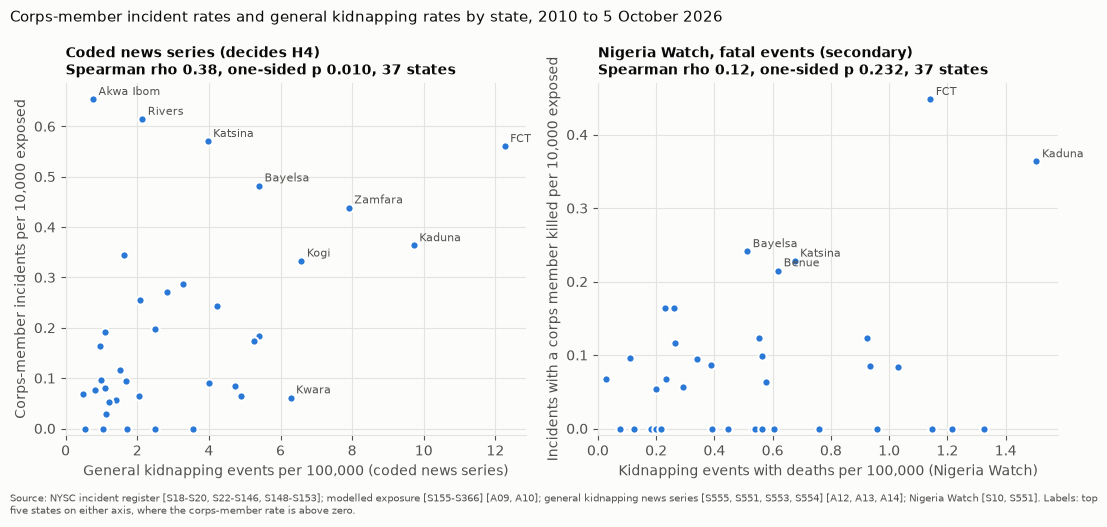

In [12]:
gk_sources = "S555, S551, S553, S554"
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), sharey=False)
panels = [
    (axes[0], main_frame, h4.iloc[0], "General kidnapping events per 100,000 (coded news series)", "Coded news series (decides H4)"),
    (axes[1], nw_frame, h4.iloc[1], "Kidnapping events with deaths per 100,000 (Nigeria Watch)", "Nigeria Watch, fatal events (secondary)"),
]
for ax, frame, result, xlabel, title in panels:
    ax.scatter(frame["general_rate"], frame["nysc_rate"], s=36, color=figures.SERIES[0], edgecolor="white", linewidth=1.5, zorder=3)
    label = frame[((frame["rank_nysc"] <= 5) | (frame["rank_general"] <= 5)) & (frame["nysc_rate"] > 0)]
    for _, row in label.iterrows():
        ax.annotate(row["state"], (row["general_rate"], row["nysc_rate"]), xytext=(4, 3), textcoords="offset points",
                    fontsize=8, color=figures.TEXT_SECONDARY)
    ax.set_xlabel(xlabel)
    ax.set_title(f"{title}\nSpearman rho {result['rho']:.2f}, one-sided p {result['p_value_one_sided']:.3f}, {int(result['n_states'])} states",
                 fontsize=10, loc="left")
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=-0.02 * frame["nysc_rate"].max())
axes[0].set_ylabel("Corps-member incidents per 10,000 exposed")
axes[1].set_ylabel("Incidents with a corps member killed per 10,000 exposed")
fig.suptitle("Corps-member incident rates and general kidnapping rates by state, 2010 to 5 October 2026", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
figures.save(fig, "h4_nysc_vs_general_kidnapping_by_state",
             f"NYSC incident register [{incident_sources}]; modelled exposure [{exposure_sources}] [A09, A10]; "
             f"general kidnapping news series [{gk_sources}] [A12, A13, A14]; Nigeria Watch [S10, S551]. Labels: top five states on either axis, where the corps-member rate is above zero.")
plt.show()

### H4 result

Coded news series (decides H4): across the 37 states, the corps-member incident rate per 10,000 exposed and the general kidnapping rate per 100,000 population are positively correlated (Spearman rho = 0.38, bootstrap 95% interval 0.05 to 0.65, one-sided p = 0.010). H4 is supported. The association is moderate: states with more general kidnapping tend to have higher corps-member incident rates, but the general rate leaves most of the variation in state ranks unexplained.

The FCT, Kaduna and Zamfara rank in the top three for general kidnapping and in the top seven for corps-member incidents. Akwa Ibom and Rivers have the highest corps-member rates but low general kidnapping rates (0.8 and 2.2 per 100,000). In Rivers 8 of the 10 register incidents are kidnappings, so the register records kidnappings of corps members there that the general series, coded from headlines, does not reflect in proportion; Akwa Ibom's 8 incidents span six harm types. Kwara and Niger have high general kidnapping rates (6.3 and 4.9 per 100,000) but low corps-member rates (0.06 per 10,000 each).

Robustness: the result is unchanged with the mean 2010 to 2022 population as denominator (rho = 0.38, p = 0.010) [A12]. Without the five states with the most register incidents (the FCT, Rivers, Akwa Ibom, Bayelsa and Katsina) the correlation across the remaining 32 states is slightly stronger (rho = 0.43, p = 0.007). Under A09 the two-year exposure window multiplies every state's exposure by the same factor in each year, so state rates and ranks, and therefore rho, are identical to the main result; it is reported because it was pre-registered.

Nigeria Watch (secondary): the rate of incidents in which a corps member was killed (41 incidents) shows no clear association with the rate of fatal kidnapping events (rho = 0.12, 95% interval -0.24 to 0.45, p = 0.23), and none without the five states (rho = 0.01, p = 0.47). With 41 incidents, 16 states have a rate of zero, so the test has little power. The two series also measure different things: Nigeria Watch counts kidnapping events with any death, including deaths of suspected kidnappers, while the register subset counts deaths of corps members from any harm.

Exploratory, not pre-registered: with only the 35 register incidents coded as kidnapping, the correlation with the coded news series is weaker and not significant (rho = 0.24, 95% interval -0.08 to 0.53, p = 0.077). The supported H4 result therefore rests on all harm types, not on kidnappings of corps members alone.

Limits: the general series is coded from headlines with a screening precision of 85.5% (80.0% to 89.7%) and assigns no state to 27% of kept headlines [A13]; recall is unknown. The general series comes from the same three outlets as the archive search behind most of the register. Shared reporting bias makes the two series comparable, but it can also produce a correlation: an outlet that covers some states more closely reports more incidents of both kinds there. Daily Trust, which reports 59% of the general kidnapping events with a state, is based in Abuja and covers the north more closely.
